# NFL Passing Performance Analysis (2000–2025)

## Research Objective

Examine how passing production has changed throughout
26 NFL regular seasons.

## Research Questions

1. How has average passing yards per team-game changed?
2. Has the variability in passing production changed?
3. How have skewness and excess kurtosis evolved?
4. How do passing-yard distributions compare across eras?
5. How do passing and rushing trends differ?

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

ROOT = Path.cwd()

if ROOT.name == "exploratory_analysis":
    ROOT = ROOT.parent.parent
elif ROOT.name == "notebooks":
    ROOT = ROOT.parent

team_stats = pd.read_parquet(
    ROOT / "data" / "processed" / "team_stats_2000_2025.parquet"
)

In [2]:
#passing yards extraction per game (not team yet)
passing = team_stats[
    ["season", "team", "week", "passing_yards"]
].dropna()

display(passing["passing_yards"].describe())


count    13418.000000
mean       236.899314
std         76.415073
min         -7.000000
25%        183.000000
50%        232.000000
75%        287.000000
max        673.000000
Name: passing_yards, dtype: float64

In [3]:
passing_summary = (
    passing.groupby("season")["passing_yards"]
    .agg(
        count="count",
        mean="mean",
        median="median",
        std="std",
        variance="var",
        minimum="min",
        maximum="max",
        skewness="skew",
        kurtosis=pd.Series.kurt
    )
    .reset_index()
)

passing_summary["Q1"] = (
    passing.groupby("season")["passing_yards"]
    .quantile(0.25)
    .values
)

passing_summary["Q3"] = (
    passing.groupby("season")["passing_yards"]
    .quantile(0.75)
    .values
)

passing_summary["IQR"] = (
    passing_summary["Q3"] - passing_summary["Q1"]
)


display(passing_summary.round(2))

,season,count,mean,median,std,variance,minimum,maximum,skewness,kurtosis,Q1,Q3,IQR
0,2000,492,222.28,216.0,76.83,5902.24,33,504,0.45,0.52,171.00,269.00,98.00
1,2001,488,224.67,219.0,79.77,6363.78,34,673,0.92,2.56,168.00,269.00,101.00
2,2002,504,230.56,221.0,76.15,5798.61,33,473,0.41,0.12,181.00,281.25,100.25
3,2003,512,213.94,211.0,73.82,5449.06,35,421,0.28,-0.15,159.75,263.25,103.50
4,2004,512,225.28,219.0,79.91,6385.41,47,499,0.56,0.34,169.00,269.25,100.25
5,2005,512,218.21,216.0,72.96,5322.58,28,458,0.23,-0.22,165.00,263.00,98.00
6,2006,512,219.24,216.0,73.92,5464.53,32,510,0.35,0.38,168.75,266.00,97.25
7,2007,512,228.21,225.0,73.40,5387.17,34,486,0.23,-0.14,174.75,278.00,103.25
8,2008,512,224.19,217.0,72.32,5230.09,26,472,0.38,0.07,172.00,275.25,103.25
9,2009,512,232.26,231.0,81.14,6582.89,-7,503,0.11,-0.18,174.00,286.00,112.00


In [10]:

from scipy.stats import t
import numpy as np

# Calculate 95% confidence intervals for seasonal means
passing_ci = passing_summary[
    ["season", "count", "mean", "std"]
].copy()

confidence_level = 0.95
alpha = 1 - confidence_level

# Standard error of each seasonal mean
passing_ci["SE"] = (
    passing_ci["std"] / np.sqrt(passing_ci["count"])
)

# Critical t-value
passing_ci["t_critical"] = t.ppf(
    1 - alpha / 2,
    df=passing_ci["count"] - 1
)

# Margin of error
passing_ci["margin_error"] = (
    passing_ci["t_critical"] * passing_ci["SE"]
)

# Lower and upper confidence bounds
passing_ci["CI_lower"] = (
    passing_ci["mean"] - passing_ci["margin_error"]
)

passing_ci["CI_upper"] = (
    passing_ci["mean"] + passing_ci["margin_error"]
)

# Display the results
display(
    passing_ci[
        ["season", "count", "mean", "std",
         "SE", "CI_lower", "CI_upper"]
    ].round(2)
)


,season,count,mean,std,SE,CI_lower,CI_upper
0,2000,492,222.28,76.83,3.46,215.48,229.09
1,2001,488,224.67,79.77,3.61,217.57,231.77
2,2002,504,230.56,76.15,3.39,223.89,237.22
3,2003,512,213.94,73.82,3.26,207.53,220.35
4,2004,512,225.28,79.91,3.53,218.34,232.22
5,2005,512,218.21,72.96,3.22,211.88,224.55
6,2006,512,219.24,73.92,3.27,212.83,225.66
7,2007,512,228.21,73.40,3.24,221.84,234.59
8,2008,512,224.19,72.32,3.20,217.91,230.47
9,2009,512,232.26,81.14,3.59,225.21,239.30


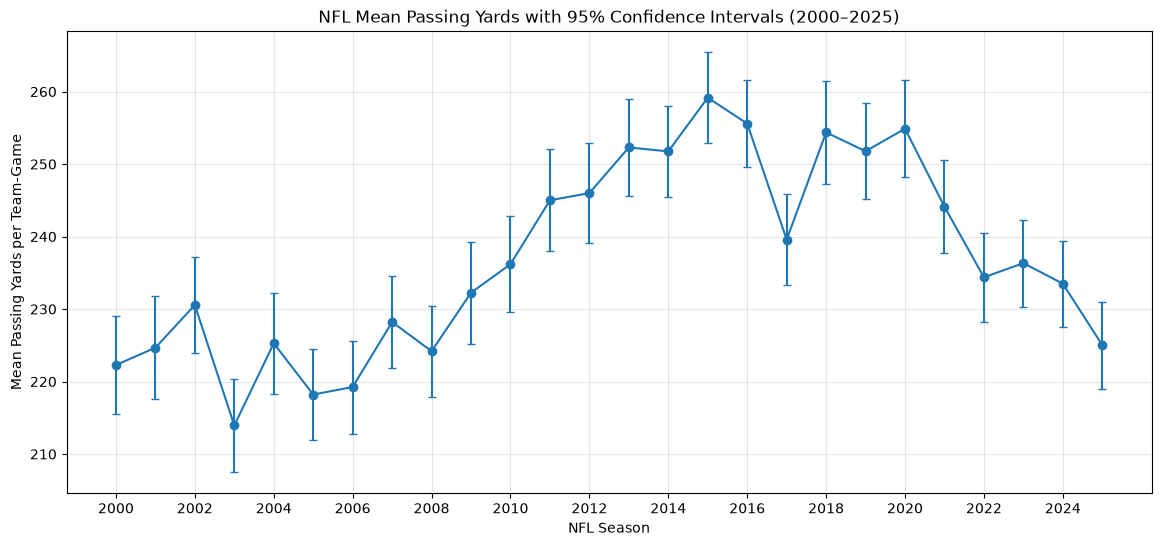

In [12]:

plt.figure(figsize=(14, 6))

plt.errorbar(
    passing_ci["season"],
    passing_ci["mean"],
    yerr=passing_ci["margin_error"],
    fmt="o-",
    capsize=3
)

plt.title("NFL Mean Passing Yards with 95% Confidence Intervals (2000–2025)")
plt.xlabel("NFL Season")
plt.ylabel("Mean Passing Yards per Team-Game")
plt.xticks(range(2000, 2026, 2))
plt.grid(alpha=0.3)

plt.show()


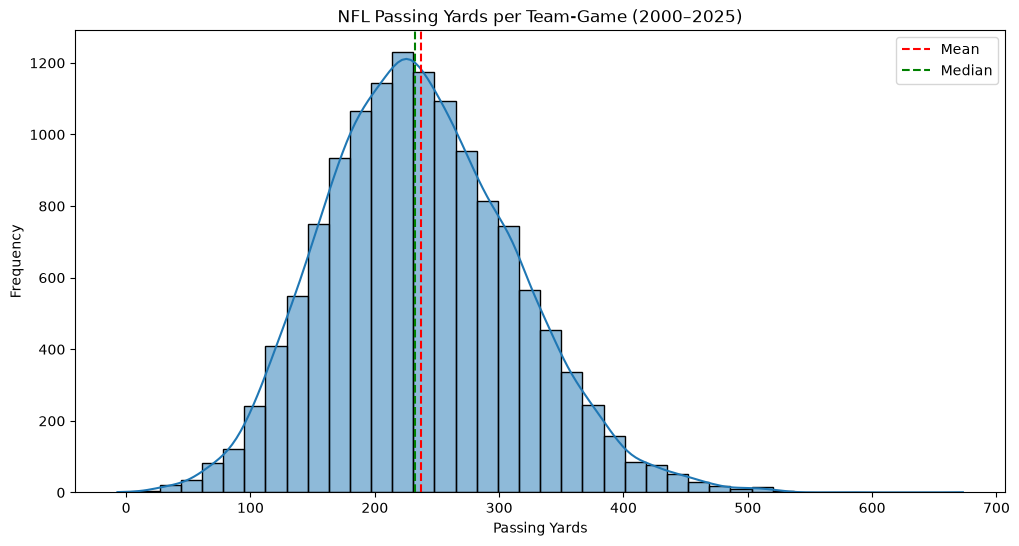

In [4]:
#plotting the overall distrbution 


plt.figure(figsize=(12, 6))

sns.histplot(
    data=passing,
    x="passing_yards",
    bins=40,
    kde=True
)

plt.axvline(
    passing["passing_yards"].mean(),
    color="red",
    linestyle="--",
    label="Mean"
)

plt.axvline(
    passing["passing_yards"].median(),
    color="green",
    linestyle="--",
    label="Median"
)

plt.title("NFL Passing Yards per Team-Game (2000–2025)")
plt.xlabel("Passing Yards")
plt.ylabel("Frequency")
plt.legend()
plt.show()

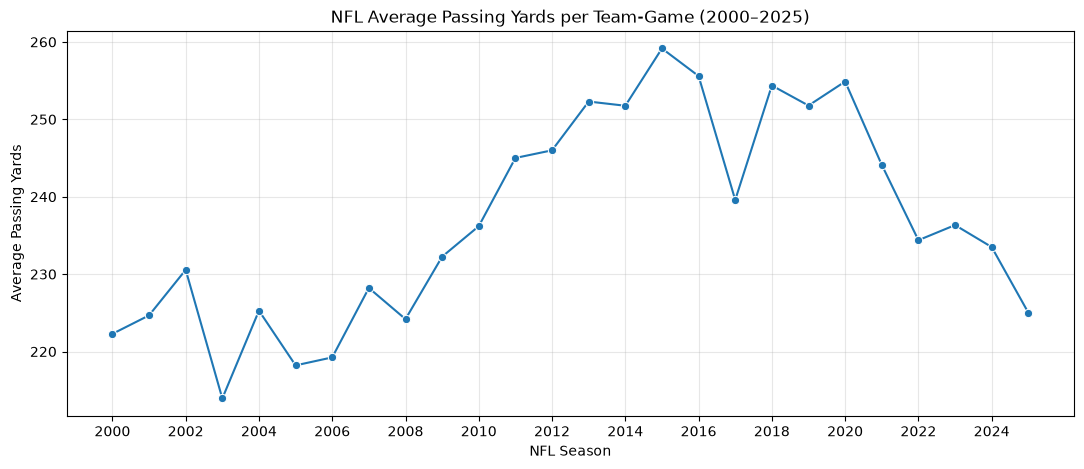

In [7]:
plt.figure(figsize=(13, 5))

sns.lineplot(
    data=passing_summary,
    x="season",
    y="mean",
    marker="o"
)

plt.title("NFL Average Passing Yards per Team-Game (2000–2025)")
plt.xlabel("NFL Season")
plt.ylabel("Average Passing Yards")
plt.xticks(range(2000, 2026, 2))
plt.grid(alpha=0.3)

plt.show()

### Historical Trends in Mean Passing Production (2000–2025)

The figure illustrates league-wide average passing yards per team-game across 26 NFL regular seasons, from 2000 through 2025.

Across the study period, the pooled mean passing production was **236.90 yards per team-game**, with a median of **232.00 yards**. However, seasonal passing averages exhibited substantial changes over time.

Between 2000 and 2008, passing production generally fluctuated between approximately 214 and 230 yards per team-game, with the **lowest seasonal mean recorded in 2003 (213.94 yards)**.

From 2009 through 2015, the league experienced a pronounced increase in average passing production, culminating in the **highest seasonal mean of 259.16 yards per team-game in 2015**.

Between 2016 and 2020, passing averages remained comparatively elevated but fluctuated across seasons, including a notable decline in 2017 followed by a recovery in 2018.

Beginning in 2021, passing production generally declined, reaching **225.02 yards per team-game in 2025**, although a modest increase occurred in 2023.

Comparing the study endpoints, average passing production increased from **222.28 yards in 2000 to 225.02 yards in 2025**, representing a net increase of approximately **1.23%**.

**Statistical interpretation:** The historical pattern indicates that passing production did not follow a consistent linear trajectory. Instead, the data exhibit an extended period of increasing production, followed by fluctuations and a more recent decline.

Although the endpoint comparison suggests little overall change, it obscures the substantially higher passing averages observed during the middle of the study period.

Further statistical analysis would be necessary to evaluate the significance of these historical changes and identify factors associated with the observed patterns.


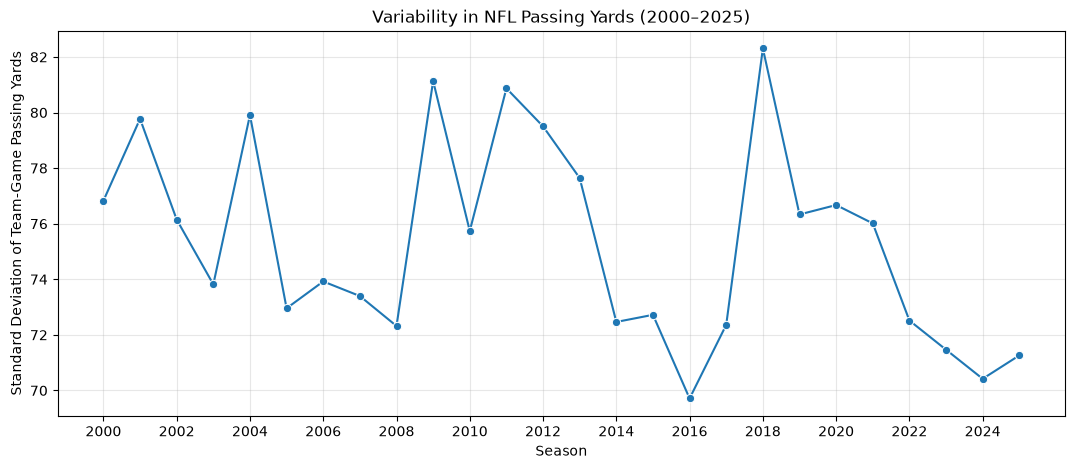

In [8]:
# variability plot
plt.figure(figsize=(13, 5))

sns.lineplot(
    data=passing_summary,
    x="season",
    y="std",
    marker="o"
)

plt.title("Variability in NFL Passing Yards (2000–2025)")
plt.xlabel("Season")
plt.ylabel("Standard Deviation of Team-Game Passing Yards")
plt.xticks(range(2000, 2026, 2))
plt.grid(alpha=0.3)

plt.show()

### Historical Variability in NFL Passing Production (2000–2025)

The figure illustrates the annual standard deviation of passing yards per team-game across 26 NFL regular seasons, from 2000 through 2025.

Seasonal standard deviations ranged from **69.71 to 82.31 passing yards**, indicating that the dispersion of individual team-game passing performances varied throughout the study period.

The **highest standard deviation occurred in 2018 (82.31 yards)**, reflecting the greatest observed dispersion around that season's league-wide mean. Conversely, the **lowest occurred in 2016 (69.71 yards)**, indicating comparatively less dispersion.

Between 2000 and 2008, passing-yard variability fluctuated, with notable increases in 2001 and 2004.

From 2009 through 2013, several seasons exhibited elevated standard deviations, particularly 2009 and 2011, when variability exceeded 80 yards.

Between 2014 and 2018, dispersion declined to its historical minimum in 2016 before increasing sharply to its maximum in 2018.

From 2019 through 2025, passing-yard standard deviations generally decreased, reaching approximately 70–71 yards during the final two seasons.

**Statistical interpretation:** The results indicate that variability in NFL passing production changed considerably throughout the study period, without a consistent upward or downward trend across all 26 seasons.

Furthermore, the season with the highest average passing production (2015) differed from the season with the greatest variability (2018), demonstrating that higher average production does not necessarily correspond to greater dispersion.

Because these statistics are calculated across pooled team-game observations within each season, the standard deviations reflect both **between-team differences** and **within-team game-to-game fluctuations**. The current analysis does not distinguish these components.

Future team-season analysis will help determine whether variability is primarily associated with differences between NFL teams or changes in individual teams' performances across games.

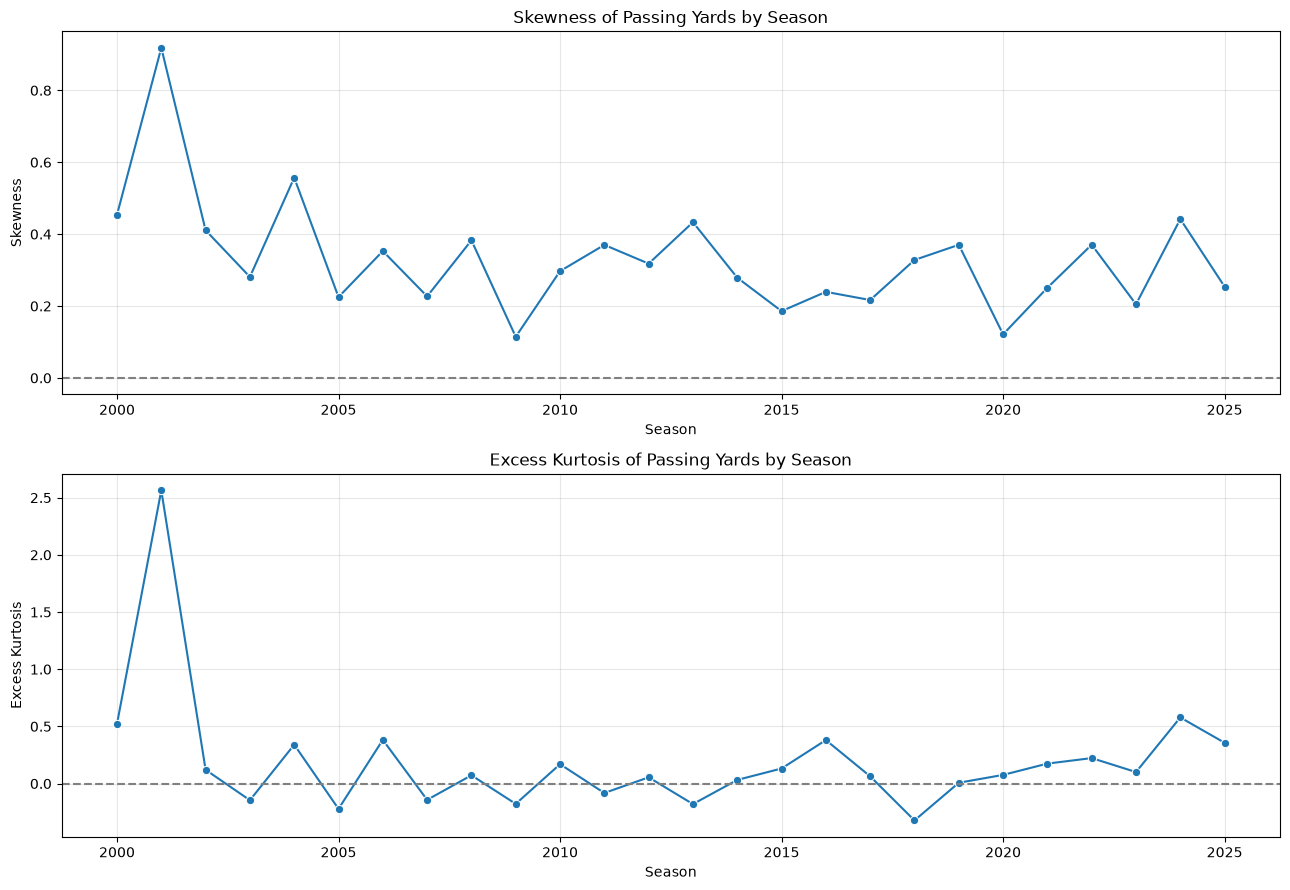

In [9]:

# Historical skewness and excess kurtosis of passing yards

fig, axes = plt.subplots(2, 1, figsize=(13, 9))

# Skewness by season
sns.lineplot(
    data=passing_summary,
    x="season",
    y="skewness",
    marker="o",
    ax=axes[0]
)

axes[0].axhline(0, color="gray", linestyle="--")
axes[0].set_title("Skewness of Passing Yards by Season")
axes[0].set_xlabel("Season")
axes[0].set_ylabel("Skewness")
axes[0].grid(alpha=0.3)

# Excess kurtosis by season
sns.lineplot(
    data=passing_summary,
    x="season",
    y="kurtosis",
    marker="o",
    ax=axes[1]
)

axes[1].axhline(0, color="gray", linestyle="--")
axes[1].set_title("Excess Kurtosis of Passing Yards by Season")
axes[1].set_xlabel("Season")
axes[1].set_ylabel("Excess Kurtosis")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


### Historical Skewness in NFL Passing Production (2000–2025)

The figure illustrates annual skewness in passing yards per team-game across 26 NFL regular seasons.

All seasons exhibited **positive skewness**, indicating that passing-yard distributions consistently displayed longer right tails toward relatively high passing-yard performances.

The greatest positive skewness occurred in **2001 (approximately 0.92)**, while the lowest occurred in **2009 (approximately 0.11)**.

Between 2000 and 2004, several seasons demonstrated relatively pronounced positive skewness. From 2005 onward, skewness generally fluctuated at lower positive values, although occasional increases remained evident.

The pooled distribution across all 26 seasons exhibited a skewness coefficient of **0.328**, indicating modest positive asymmetry.

**Statistical interpretation:** NFL passing-yard distributions remained positively skewed throughout the study period, although the magnitude of this asymmetry varied across seasons.

The persistent positive skewness suggests that relatively high passing-yard performances contributed to longer upper tails. However, the statistic alone does not identify the teams responsible for these performances or establish their frequency.

No consistent historical increase or decrease in skewness is evident from the figure.



### Historical Excess Kurtosis in NFL Passing Production (2000–2025)

The figure illustrates annual excess kurtosis in passing yards per team-game across 26 NFL regular seasons.

Unlike skewness, excess kurtosis fluctuated between positive and negative values throughout the study period.

The highest excess kurtosis occurred in **2001 (approximately 2.57)**, substantially exceeding the normal-distribution reference of zero. This season also exhibited the greatest positive skewness, suggesting that unusually high passing-yard observations may have contributed strongly to the distribution's shape.

The lowest excess kurtosis occurred in **2018 (approximately −0.32)**.

Outside the pronounced 2001 peak, annual excess kurtosis generally remained relatively close to zero, with modest positive and negative fluctuations.

The pooled passing-yard distribution exhibited **excess kurtosis of 0.169**, indicating a fourth standardized moment slightly above the normal-distribution reference.

**Statistical interpretation:** The results suggest that the tail behavior of passing-yard distributions varied across seasons, although most annual excess kurtosis values remained relatively modest.

The unusually elevated value in 2001 warrants further investigation of individual team-game passing performances to determine which observations contributed most strongly to the result.

Because excess kurtosis alone does not establish normality or identify specific outliers, additional distributional diagnostics would be necessary to characterize these differences more precisely.

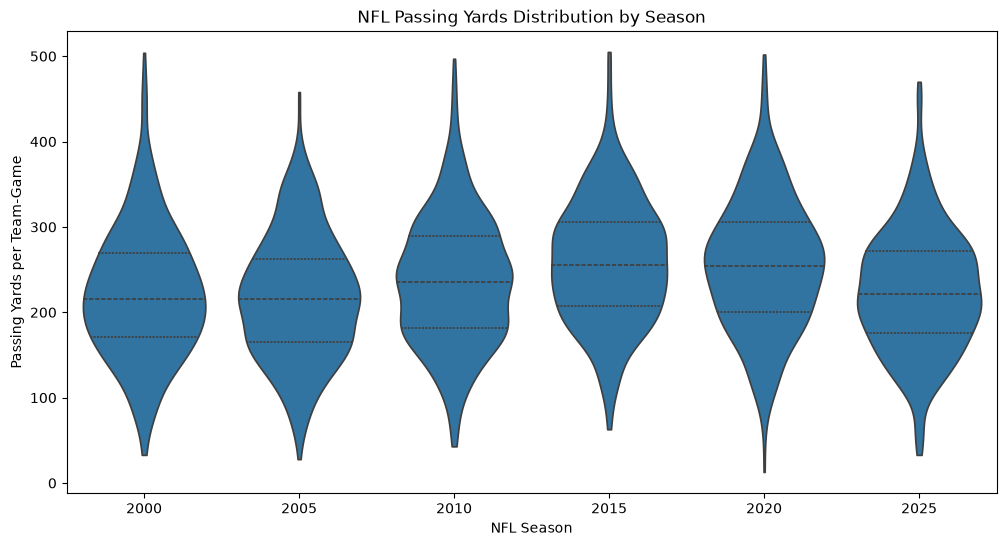

,season,count,mean,median,std,variance,Q1,Q3,IQR,skewness,kurtosis
0,2000,492,222.28,216.0,76.83,5902.24,171.00,269.00,98.00,0.45,0.52
5,2005,512,218.21,216.0,72.96,5322.58,165.00,263.00,98.00,0.23,-0.22
10,2010,512,236.20,235.5,75.74,5736.19,182.00,289.25,107.25,0.30,0.17
15,2015,512,259.16,256.0,72.72,5288.39,207.00,306.25,99.25,0.19,0.13
20,2020,512,254.88,254.0,76.67,5878.58,200.75,305.50,104.75,0.12,0.08
25,2025,544,225.02,221.0,71.26,5078.30,175.75,272.00,96.25,0.25,0.36


In [5]:
selected_years = [2000, 2005, 2010, 2015, 2020, 2025]

subset = passing.loc[
    passing["season"].isin(selected_years)
].copy()

plt.figure(figsize=(12, 6))

sns.violinplot(
    data=subset,
    x="season",
    y="passing_yards",
    inner="quartile",
    cut=0
)

plt.title("NFL Passing Yards Distribution by Season")
plt.xlabel("NFL Season")
plt.ylabel("Passing Yards per Team-Game")

plt.show()

#showing the descriptive stats for each of these selected years
selected_stats = passing_summary.loc[
    passing_summary["season"].isin(selected_years)
]

display(
    selected_stats[
        [
            "season", "count", "mean", "median",
            "std", "variance", "Q1", "Q3",
            "IQR", "skewness", "kurtosis"
        ]
    ].round(2)
)

### Distributional Comparison of Selected NFL Passing Seasons (2000–2025)

The violin plots compare passing yards per team-game across six selected NFL regular seasons: **2000, 2005, 2010, 2015, 2020, and 2025**.

Each violin represents an estimated probability density of passing-yard performances within a given season. Wider regions indicate greater concentrations of team-game observations at particular passing-yard values, while narrower regions indicate lower estimated density.

The internal horizontal lines represent the first quartile (Q1), median, and third quartile (Q3), allowing comparisons of central tendency and dispersion.

**Central Tendency**

The 2015 and 2020 distributions are centered at comparatively higher passing-yard totals than those of 2000, 2005, and 2025.

The 2015 season recorded the highest league-wide average passing production across the full study period, at **259.16 yards per team-game**, whereas the 2025 average was **225.02 yards per team-game**.

**Variability and Distribution Shape**

All six distributions exhibit substantial variation in team-game passing production, with considerable overlap between their interquartile ranges.

The distributions generally display positively skewed shapes, with upper tails extending toward relatively high passing-yard totals. These patterns are consistent with the positive seasonal skewness identified earlier.

Although the 2015 and 2020 distributions exhibit higher centers, substantial overlap remains between seasons, indicating that differences in seasonal averages do not imply that individual team-game performances were uniformly higher.

**Statistical Interpretation**

The violin plots reinforce the historical trend analysis by illustrating differences in distributional location, spread, and shape across selected seasons.

The results suggest that the elevated passing production observed during the mid-to-late 2010s reflected a broader shift in the distribution's center, rather than merely an isolated increase in its maximum values.

However, descriptive visualizations alone cannot establish the statistical significance of differences between seasons or identify the underlying factors responsible for those differences.

Further team-level and matchup-based analysis will help investigate the sources of variation in passing production.

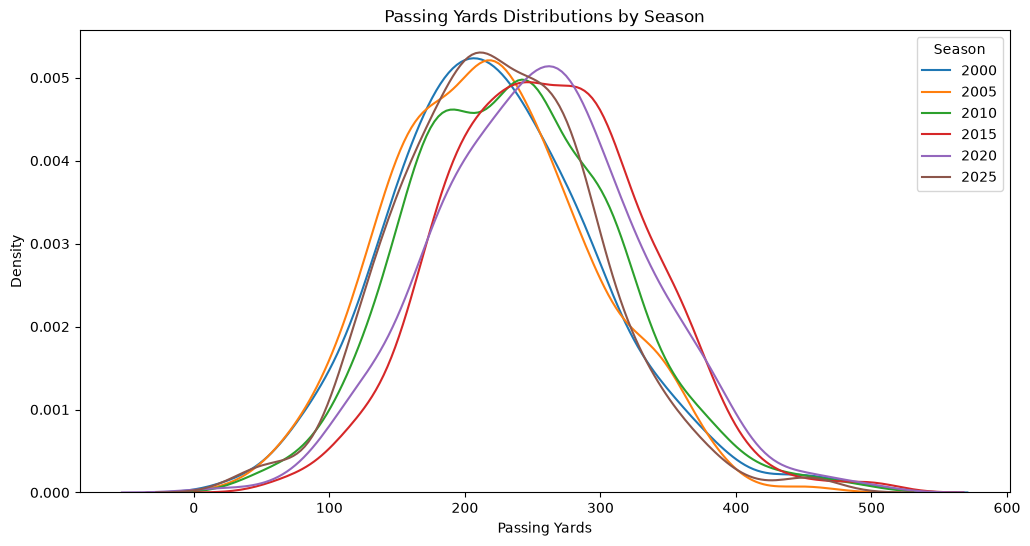

In [11]:
selected_years = [2000, 2005, 2010, 2015, 2020, 2025]

plt.figure(figsize=(12, 6))

for season in selected_years:
    season_data = passing.loc[passing["season"] == season, "passing_yards"]
    sns.kdeplot(season_data, label=str(season), fill=False)

plt.title("Passing Yards Distributions by Season")
plt.xlabel("Passing Yards")
plt.ylabel("Density")
plt.legend(title="Season")
plt.show()

In [6]:

# Summary of historical passing performance

summary = passing_summary.copy()

highest_mean = summary.loc[summary["mean"].idxmax()]
lowest_mean = summary.loc[summary["mean"].idxmin()]

highest_std = summary.loc[summary["std"].idxmax()]
lowest_std = summary.loc[summary["std"].idxmin()]

mean_2000 = summary.loc[
    summary["season"] == 2000, "mean"
].iloc[0]

mean_2025 = summary.loc[
    summary["season"] == 2025, "mean"
].iloc[0]

print("NFL PASSING PERFORMANCE: 2000–2025")
print("-" * 45)

print(f"Overall Mean: {passing['passing_yards'].mean():.2f}")
print(f"Overall Median: {passing['passing_yards'].median():.2f}")

print(f"Highest Mean: {int(highest_mean['season'])} ({highest_mean['mean']:.2f})")
print(f"Lowest Mean: {int(lowest_mean['season'])} ({lowest_mean['mean']:.2f})")

print(f"Highest SD: {int(highest_std['season'])} ({highest_std['std']:.2f})")
print(f"Lowest SD: {int(lowest_std['season'])} ({lowest_std['std']:.2f})")

print(f"2000 Mean: {mean_2000:.2f}")
print(f"2025 Mean: {mean_2025:.2f}")
print(f"Absolute Change: {mean_2025 - mean_2000:+.2f}")
print(f"Percentage Change: {(mean_2025 / mean_2000 - 1) * 100:+.2f}%")

print(f"Overall Skewness: {passing['passing_yards'].skew():.3f}")
print(f"Overall Excess Kurtosis: {passing['passing_yards'].kurt():.3f}")


NFL PASSING PERFORMANCE: 2000–2025
---------------------------------------------
Overall Mean: 236.90
Overall Median: 232.00
Highest Mean: 2015 (259.16)
Lowest Mean: 2003 (213.94)
Highest SD: 2018 (82.31)
Lowest SD: 2016 (69.71)
2000 Mean: 222.28
2025 Mean: 225.02
Absolute Change: +2.74
Percentage Change: +1.23%
Overall Skewness: 0.328
Overall Excess Kurtosis: 0.169


## Conclusion: Historical NFL Passing Performance (2000–2025)

This analysis examined league-wide passing production across 26 NFL regular seasons, from 2000 through 2025. Using individual team-game observations, the study investigated historical changes in passing production, game-to-game variability, and distributional characteristics.

### Summary of Findings

**Central Tendency and Historical Trends**

Across the study period, the pooled average passing production was **236.90 yards per team-game**, with a median of **232.00 yards**.

Seasonal passing averages exhibited a noticeable historical pattern. Passing production was generally lower during the early 2000s, increased substantially through the early-to-mid 2010s, and declined during the final years of the study period.

The highest seasonal average occurred in **2015 (259.16 yards per team-game)**, while the lowest occurred in **2003 (213.94 yards per team-game)**.

Although average passing production increased from **222.28 yards in 2000 to 225.02 yards in 2025**, representing a net increase of approximately **1.23%**, this comparison obscures the substantially higher averages recorded during the middle of the study period.

**Variability in Passing Production**

Seasonal standard deviations ranged from **69.71 yards in 2016** to **82.31 yards in 2018**, indicating changes in the dispersion of individual team-game passing performances.

Variability fluctuated throughout the study period, without a consistent increasing or decreasing trend across all 26 seasons.

Notably, the season with the highest average passing production (2015) differed from the season with the greatest standard deviation (2018), demonstrating that higher average production does not necessarily correspond to greater dispersion.

**Distributional Characteristics**

The pooled passing-yard distribution exhibited **positive skewness (0.328)** and **slightly positive excess kurtosis (0.169)**.

Positive skewness was observed in every season, indicating that passing-yard distributions consistently exhibited longer right tails toward higher passing-yard totals.

Excess kurtosis varied between positive and negative values, with the highest value observed in **2001 (approximately 2.57)**. This suggests that the influence of extreme observations on the fourth standardized moment differed across seasons.

The selected violin plots further demonstrated differences in the centers, spreads, and shapes of passing-yard distributions, while also revealing considerable overlap between seasons.

### Statistical Limitations

The findings are primarily descriptive and do not establish causal relationships or statistically significant differences between seasons.

Because the dataset consists of individual team-game observations, the reported seasonal standard deviations reflect both differences between teams and fluctuations within teams across games.

Furthermore, changes in offensive strategies, opponent strength, league rules, and game situations may have influenced the observed historical patterns.

Although conventional confidence intervals were calculated as an exploratory extension, the dependence between observations should be considered before drawing formal inferential conclusions.

### Future Research

Future investigations will extend the league-wide analysis to individual team-season averages and game-level matchups.

These analyses will help identify consistently productive passing offenses, distinguish between-team and within-team variability, and evaluate how offensive production relates to opposing defenses.

The historical findings established in this notebook provide a statistical baseline for the broader *Beyond the Chains* project, which will eventually incorporate player-level performance evaluation, statistical inference, and predictive modeling.